In [13]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import yaml
import os

In [14]:
import torch
from deep_hedging.black_scholes import black_scholes_call_price

In [15]:
entropic_run_path = Path("../runs/entropic_nocost_seed0")
cvar_run_path = Path("../runs/cvar_nocost_seed0")

In [16]:
entropic_loss_path = os.path.join(entropic_run_path, "model_history.csv")
entropic_loss = pl.read_csv(entropic_loss_path)
print(entropic_loss)

cvar_loss_path = os.path.join(cvar_run_path, "model_history.csv")
cvar_loss = pl.read_csv(cvar_loss_path)
print(cvar_loss)

shape: (2_000, 1)
┌───────────┐
│ loss      │
│ ---       │
│ f64       │
╞═══════════╡
│ 14.313739 │
│ 13.99348  │
│ 17.475082 │
│ 12.807046 │
│ 11.973056 │
│ …         │
│ 2.4383    │
│ 2.469373  │
│ 2.456273  │
│ 2.452889  │
│ 2.464328  │
└───────────┘
shape: (2_000, 1)
┌──────────┐
│ loss     │
│ ---      │
│ f64      │
╞══════════╡
│ 5.050418 │
│ 5.02142  │
│ 5.455573 │
│ 5.191586 │
│ 5.129601 │
│ …        │
│ 2.659975 │
│ 2.663345 │
│ 2.677938 │
│ 2.655772 │
│ 2.688707 │
└──────────┘


In [17]:
entropic_loss = entropic_loss.with_columns(pl.col("loss").rolling_mean(window_size=100, min_samples=1).alias("loss_rolling_mean"))
entropic_loss = entropic_loss.with_row_index("iter")
print(entropic_loss.head())

cvar_loss = cvar_loss.with_columns(pl.col("loss").rolling_mean(window_size=100, min_samples=1).alias("loss_rolling_mean"))
cvar_loss = cvar_loss.with_row_index("iter")
print(cvar_loss.head())

shape: (5, 3)
┌──────┬───────────┬───────────────────┐
│ iter ┆ loss      ┆ loss_rolling_mean │
│ ---  ┆ ---       ┆ ---               │
│ u32  ┆ f64       ┆ f64               │
╞══════╪═══════════╪═══════════════════╡
│ 0    ┆ 14.313739 ┆ 14.313739         │
│ 1    ┆ 13.99348  ┆ 14.153609         │
│ 2    ┆ 17.475082 ┆ 15.260767         │
│ 3    ┆ 12.807046 ┆ 14.647337         │
│ 4    ┆ 11.973056 ┆ 14.112481         │
└──────┴───────────┴───────────────────┘
shape: (5, 3)
┌──────┬──────────┬───────────────────┐
│ iter ┆ loss     ┆ loss_rolling_mean │
│ ---  ┆ ---      ┆ ---               │
│ u32  ┆ f64      ┆ f64               │
╞══════╪══════════╪═══════════════════╡
│ 0    ┆ 5.050418 ┆ 5.050418          │
│ 1    ┆ 5.02142  ┆ 5.035919          │
│ 2    ┆ 5.455573 ┆ 5.175804          │
│ 3    ┆ 5.191586 ┆ 5.179749          │
│ 4    ┆ 5.129601 ┆ 5.16972           │
└──────┴──────────┴───────────────────┘


In [18]:
config_path = os.path.join(entropic_run_path, "config.yaml")

In [19]:
with open(config_path) as f:
    config = yaml.safe_load(f)

S0 = config["market"]["S0"]
mu = config["market"]["mu"]
sigma = config["market"]["sigma"]
T = config["market"]["T"]
n_steps = config["market"]["n_steps"]
K = config["option"]["K"]

bs_price = black_scholes_call_price(S=torch.tensor(S0, dtype=torch.float32), K=K, tau=torch.tensor(T, dtype=torch.float32), sigma=sigma).item()
print(bs_price)

2.2871475219726562


d:\Perso_Projects\Perso_Projects\DeepHedging\.venv\Lib\site-packages\seaborn\_core\data.py:313: UserWarning: Conversion using Arrow PyCapsule Interface failed due to missing PyArrow>=14 dependency, falling back to (deprecated) interchange protocol. We recommend that you install PyArrow>=14.0.0.
  return pd.api.interchange.from_dataframe(data)
d:\Perso_Projects\Perso_Projects\DeepHedging\.venv\Lib\site-packages\seaborn\_core\data.py:313: UserWarning: Conversion using Arrow PyCapsule Interface failed due to missing PyArrow>=14 dependency, falling back to (deprecated) interchange protocol. We recommend that you install PyArrow>=14.0.0.
  return pd.api.interchange.from_dataframe(data)
d:\Perso_Projects\Perso_Projects\DeepHedging\.venv\Lib\site-packages\seaborn\_core\data.py:313: UserWarning: Conversion using Arrow PyCapsule Interface failed due to missing PyArrow>=14 dependency, falling back to (deprecated) interchange protocol. We recommend that you install PyArrow>=14.0.0.
  return pd.ap

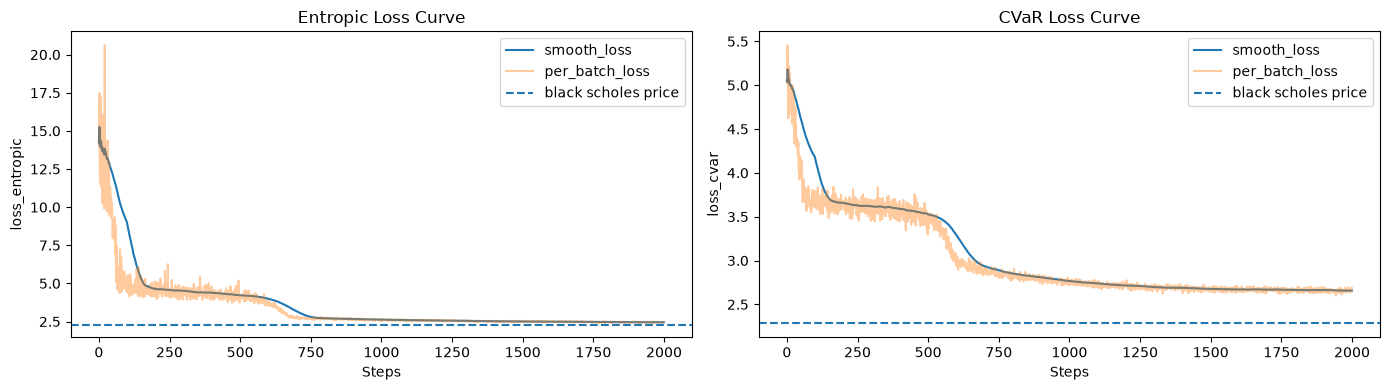

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

# Entropic Loss
sns.lineplot(data=entropic_loss, x="iter", y="loss_rolling_mean", ax=ax1, label="smooth_loss")
sns.lineplot(data=entropic_loss, x="iter", y="loss", ax=ax1, alpha=0.4, label="per_batch_loss")
ax1.axhline(bs_price, linestyle="--", label="black scholes price")
ax1.set_xlabel("Steps")
ax1.set_ylabel("loss_entropic")
ax1.set_title("Entropic Loss Curve")
ax1.legend()

# CVaR Loss
sns.lineplot(data=cvar_loss, x="iter", y="loss_rolling_mean", ax=ax2, label="smooth_loss")
sns.lineplot(data=cvar_loss, x="iter", y="loss", ax=ax2, alpha=0.4, label="per_batch_loss")
ax2.axhline(bs_price, linestyle="--", label="black scholes price")
ax2.set_xlabel("Steps")
ax2.set_ylabel("loss_cvar")
ax2.set_title("CVaR Loss Curve")
ax2.legend()

fig.tight_layout()
# fig.savefig("results/first_run_results/training_loss.png", dpi=150, bbox_inches="tight")

The Entropic plot shows that the loss plumets before stabilizing around the step 200 showing a much gentler steep until step 600.

The CVaR training loss shows a much gentler slope between steps ~200 to 550 at a loss~3.6 before further decreasing.

-> the optimizer seems to get stuck

Why does the loss stabilizes ?   

In [21]:
from deep_hedging.delta import bs_hedge_policy
from deep_hedging.risk import entropic_risk, cvar_empirical
from deep_hedging.gbm import simulate_gbm
from deep_hedging.engine import pnl
from deep_hedging.payoffs import call_payoff
from deep_hedging.nn_policy import build_nn, nn_policy
from deep_hedging.features import make_features

In [22]:
n_paths = config["test"]["n_paths"]
lam = config["risk"]["lam"]
alpha = config["risk"]["alpha"]    
torch.manual_seed(config["test_seed"])
test_t, test_S = simulate_gbm(S0, mu, sigma, T, n_steps, n_paths)

payoff_ = call_payoff(K, test_S[:,-1, 0])


entropic_loss_list = []
cvar_loss_list = []

min_entropic = 15
min_cvar = 15

cs =  torch.linspace(0.0, 1.0, 21)

for c in cs:
    delta_cst = torch.full_like(test_S[:, :-1, :], c)

    pnl_ = pnl(payoff=payoff_, S=test_S, delta=delta_cst, p0=0.0, c=0.0)
    
    temp_entropic = entropic_risk(pnl_, lam)
    
    temp_cvar = cvar_empirical(pnl_, alpha)[1]

    if temp_entropic.item() < min_entropic:
        c_star_entropic = c.item()
        min_entropic = temp_entropic.item()
    
    if temp_cvar.item() < min_cvar:
        c_star_cvar = c.item()
        min_cvar = temp_cvar.item()

    entropic_loss_list.append(temp_entropic)
    cvar_loss_list.append(temp_cvar)

print(f"Min Entropic Loss with constant Hedge: {min_entropic:.2f} attained in: {c_star_entropic:.2f}")
print(f"Min CVaR Loss with constant Hedge: {min_cvar:.2f} attained in: {c_star_cvar:.2f} ")

Min Entropic Loss with constant Hedge: 4.65 attained in: 0.55
Min CVaR Loss with constant Hedge: 3.64 attained in: 0.50 


d:\Perso_Projects\Perso_Projects\DeepHedging\.venv\Lib\site-packages\seaborn\_core\data.py:313: UserWarning: Conversion using Arrow PyCapsule Interface failed due to missing PyArrow>=14 dependency, falling back to (deprecated) interchange protocol. We recommend that you install PyArrow>=14.0.0.
  return pd.api.interchange.from_dataframe(data)
d:\Perso_Projects\Perso_Projects\DeepHedging\.venv\Lib\site-packages\seaborn\_core\data.py:313: UserWarning: Conversion using Arrow PyCapsule Interface failed due to missing PyArrow>=14 dependency, falling back to (deprecated) interchange protocol. We recommend that you install PyArrow>=14.0.0.
  return pd.api.interchange.from_dataframe(data)
d:\Perso_Projects\Perso_Projects\DeepHedging\.venv\Lib\site-packages\seaborn\_core\data.py:313: UserWarning: Conversion using Arrow PyCapsule Interface failed due to missing PyArrow>=14 dependency, falling back to (deprecated) interchange protocol. We recommend that you install PyArrow>=14.0.0.
  return pd.ap

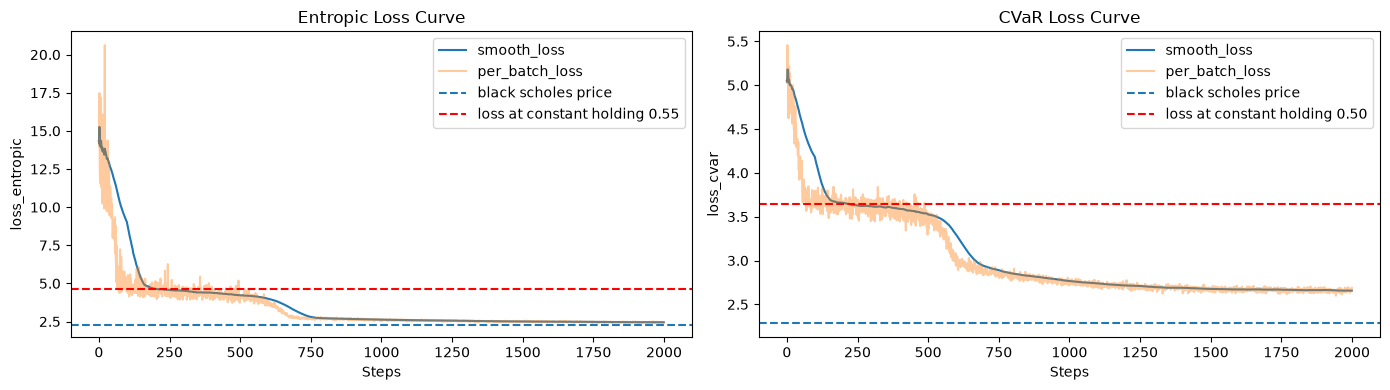

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

# Entropic Loss
sns.lineplot(data=entropic_loss, x="iter", y="loss_rolling_mean", ax=ax1, label="smooth_loss")
sns.lineplot(data=entropic_loss, x="iter", y="loss", ax=ax1, alpha=0.4, label="per_batch_loss")
ax1.axhline(bs_price, linestyle="--", label="black scholes price")
ax1.axhline(min_entropic, color="red", linestyle="--", label=f"loss at constant holding {c_star_entropic:.2f}")
ax1.set_xlabel("Steps")
ax1.set_ylabel("loss_entropic")
ax1.set_title("Entropic Loss Curve")
ax1.legend()

# CVaR Loss
sns.lineplot(data=cvar_loss, x="iter", y="loss_rolling_mean", ax=ax2, label="smooth_loss")
sns.lineplot(data=cvar_loss, x="iter", y="loss", ax=ax2, alpha=0.4, label="per_batch_loss")
ax2.axhline(bs_price, linestyle="--", label="black scholes price")
ax2.axhline(min_cvar, color="red", linestyle="--", label=f"loss at constant holding {c_star_cvar:.2f}")
ax2.set_xlabel("Steps")
ax2.set_ylabel("loss_cvar")
ax2.set_title("CVaR Loss Curve")
ax2.legend()

fig.tight_layout()
fig.savefig("results/first_run_results/training_loss.png", dpi=150, bbox_inches="tight")

seems like the NN learnt the optimal constant hedge first, the NN was ignoring S

In [24]:
# check rho_nn >= bs_price - 3 std

# For entropic nn

n_hidden = config["network"]["n_hidden"]
n_layers = config["network"]["n_layers"] 


bs_delta = bs_hedge_policy(S=test_S, K=K, T=T, t=test_t, sigma=sigma)[:,:-1,:]

features = make_features(S=test_S, t=test_t, T=T, K=K)

model_entropic = build_nn(n_inputs=3, n_outputs=1, n_hidden=n_hidden, n_layers=n_layers)

model_entropic.load_state_dict(torch.load(entropic_run_path / "model.pt"))
model_entropic.eval()
with torch.no_grad():
    nn_delta = nn_policy(model_entropic, features)

pnl_nn = pnl(payoff=payoff_, S=test_S, delta=nn_delta, p0=0.0, c=0.0)

rho_nn = []

# Bootstap se:
g = torch.Generator().manual_seed(0)
N = pnl_nn.shape[0]
for i in range(200):
    idx = torch.randint(0, N, (N,), generator=g) 
    rho_nn.append(entropic_risk(x=pnl_nn[idx], lam=lam))

se_rho_nn = torch.std(torch.stack(rho_nn))
print(se_rho_nn.item())

nn_entropic = entropic_risk(pnl_nn, lam)

print("rho_nn >= bs_price -3 * std ?", nn_entropic.item() >= bs_price - 3*se_rho_nn.item())
print(f"rho_nn: {nn_entropic.item():.4f}")
print(f"bs_price -3 * std: {bs_price - 3*se_rho_nn.item():.2f}")

 

0.0017840772634372115
rho_nn >= bs_price -3 * std ? True
rho_nn: 2.4523
bs_price -3 * std: 2.28


In [25]:
# rho_nn − rho_bs <= 0.01
pnl_nn = pnl(payoff=payoff_, S=test_S, delta=nn_delta, p0=0.0, c=0.0)
pnl_bs = pnl(payoff=payoff_, S=test_S, delta=bs_delta, p0=0.0, c=0.0)

nn_entropic = entropic_risk(pnl_nn, lam)
bs_entropic = entropic_risk(pnl_bs, lam)

print(f"rho_nn: {nn_entropic:.2f}     rho_bs: {bs_entropic:.2f}")

# standard error using bootstrap:
entropic_gaps = []
g = torch.Generator().manual_seed(0)
N = pnl_nn.shape[0]
for i in range(200):
    idx = torch.randint(0, N, (N,), generator=g) 
    entropic_gaps.append(entropic_risk(x=pnl_nn[idx], lam=lam) - entropic_risk(x=pnl_bs[idx], lam=lam))

se_gap = torch.std(torch.stack(entropic_gaps))
print(f"standard error over bootstrapped sample of pnls: {se_gap.item():.2%}")

if nn_entropic - bs_entropic > 0.01:
    print(f"Failed the test: rho_nn - rho_bs ~ {nn_entropic - bs_entropic:.4f}    with se : {se_gap.item():.2%}")
else:
    print("Test succeeded")

rho_nn: 2.45     rho_bs: 2.36
standard error over bootstrapped sample of pnls: 0.15%
Failed the test: rho_nn - rho_bs ~ 0.0973    with se : 0.15%


So under the first training settings, the NN fails.

In [26]:
# investigating where the network fails :

from ipywidgets import interact
@interact(PATH = (0, nn_delta.shape[0]-1, 1))
def plot_hedge_comp(PATH=0):
    fig, ax = plt.subplots(figsize=(14, 4))

    times = test_t[:-1]
    ynn = nn_delta[PATH,:,0]
    ybs = bs_delta[PATH,:,0]
    
    ax.plot(times, ynn , label=r"$\delta_{NN}$")
    ax.plot(times, ybs, label=r"$\delta_{BS}$")
    
    ax.fill_between(times, ynn, ybs, color='red', alpha=0.1, label=r"Error Gap: $\delta_{NN} - \delta_{BS}$")

    ax.set_xlabel("Time")
    ax.set_ylabel("Hedge ratio")
    ax.set_title("Mean Hedge Policy")
    ax.legend()
    fig.tight_layout()
    plt.show()
    fig.savefig("results/first_run_results/gap_comparision_over_option_life.png", dpi=150, bbox_inches="tight")


interactive(children=(IntSlider(value=0, description='PATH', max=99999), Output()), _dom_classes=('widget-inte…

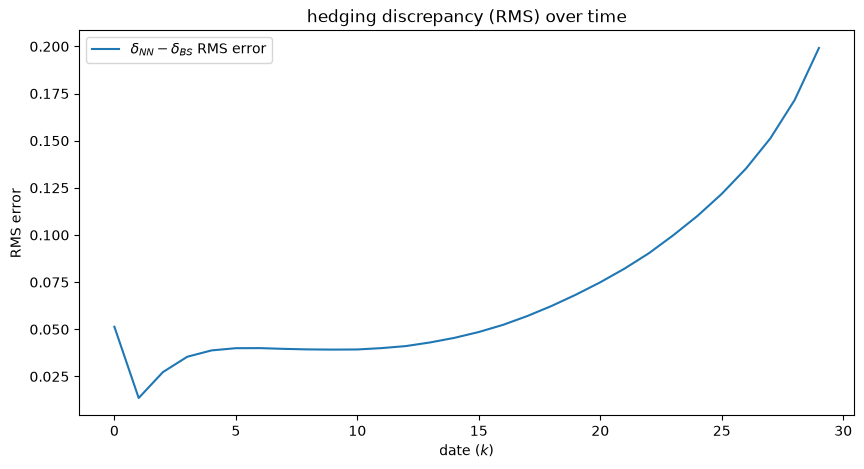

In [27]:
# we calculate the RMS of nn_delta - bs_delta at each timestep k:

delta_diff = nn_delta - bs_delta

rms_k = torch.sqrt(torch.mean(delta_diff ** 2, dim=0))

plt.figure(figsize=(10, 5))
plt.plot(rms_k, label=r"$\delta_{NN} - \delta_{BS}$ RMS error")
plt.title("hedging discrepancy (RMS) over time")
plt.xlabel("date ($k$)")
plt.ylabel("RMS error")
plt.legend()
plt.show()
fig.savefig("results/first_run_results/RMS_over_option_life.png", dpi=150, bbox_inches="tight")

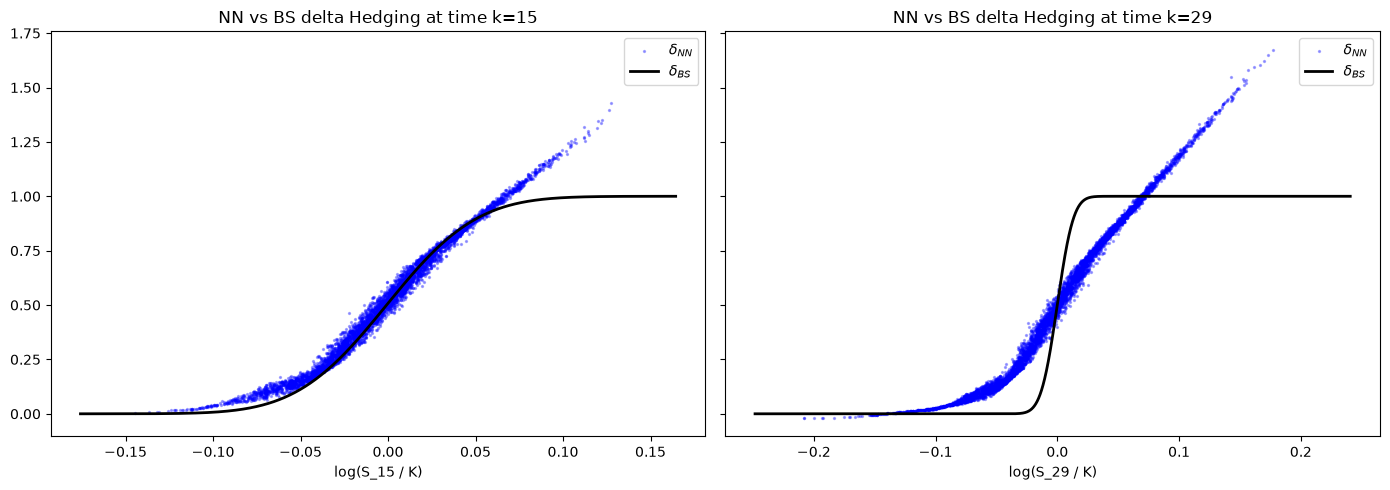

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for k, ax in zip([15, 29], axes):
    x = torch.log(test_S[:, k, 0] / K)
    y_nn = nn_delta[:, k, 0]
    y_bs = bs_delta[:, k, 0]
    
    g = torch.Generator().manual_seed(1)
    sub = torch.randperm(N, generator=g)[:5000]
    
    ax.scatter(x[sub], y_nn[sub], s=2, color="blue", alpha=0.3, label=r"$\delta_{NN}$")
    
    order = torch.argsort(x)
    ax.plot(x[order], y_bs[order], color="black", lw=2, label=r"$\delta_{BS}$")
    
    ax.set_title(f"NN vs BS delta Hedging at time k={k}")
    ax.set_xlabel(f"log(S_{k} / K)")
        
    ax.legend()

plt.tight_layout()
plt.show()
fig.savefig("results/first_run_results/delta_comparison_k15_k29.png", dpi=150, bbox_inches="tight")

First: 

* 0 <= delta <= 1 

* We see that the NN's delta goes beyond 1. While the BS delta increases and then stabilizes, the network's delta keeps on climbing.

Second: 

* At timestep 15 (mid option life), the NN delta follows the BS delta closely when it is deep in the money. However, at timestep 29 (approaching expiration), a tiny move in the stock's price drastically changes the log moneyness, resulting in a much steeper slope for the BS curve. The network completely fails to capture this sharp slope.

* Also, for both k=15 and k=29, the network draws the same delta, when we designed it semi recurrent to learn each date's delta behavior.